# Visualization Demo

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the Data

In [53]:
data = pd.read_csv("./checkpoints/TrainingStats.csv")
data.head()

,train_accuracy_scores,val_accuracy_scores,train_losses,val_losses,incumbent_trajectory
0,0.962000,0.9626,0.123222,0.116586,0.9626
1,0.975722,0.9745,0.075353,0.075152,0.9745
2,0.985519,0.9833,0.048554,0.052572,0.9833
3,0.985370,0.9827,0.045581,0.056186,0.9833
4,0.988630,0.9852,0.035765,0.047558,0.9852


In [54]:
data.describe()

,train_accuracy_scores,val_accuracy_scores,train_losses,val_losses,incumbent_trajectory
count,10.000000,10.000000,10.000000,10.000000,10.000000
mean,0.986256,0.982550,0.043897,0.055185,0.982770
std,0.010292,0.008143,0.033140,0.024325,0.008225
min,0.962000,0.962600,0.016269,0.037389,0.962600
25%,0.985407,0.982850,0.021007,0.039926,0.983300
50%,0.989407,0.985350,0.032788,0.046708,0.986150
75%,0.993602,0.987250,0.047811,0.055283,0.987250
max,0.994852,0.988700,0.123222,0.116586,0.988700


## Train/Validation Loss & Accuracy Plots

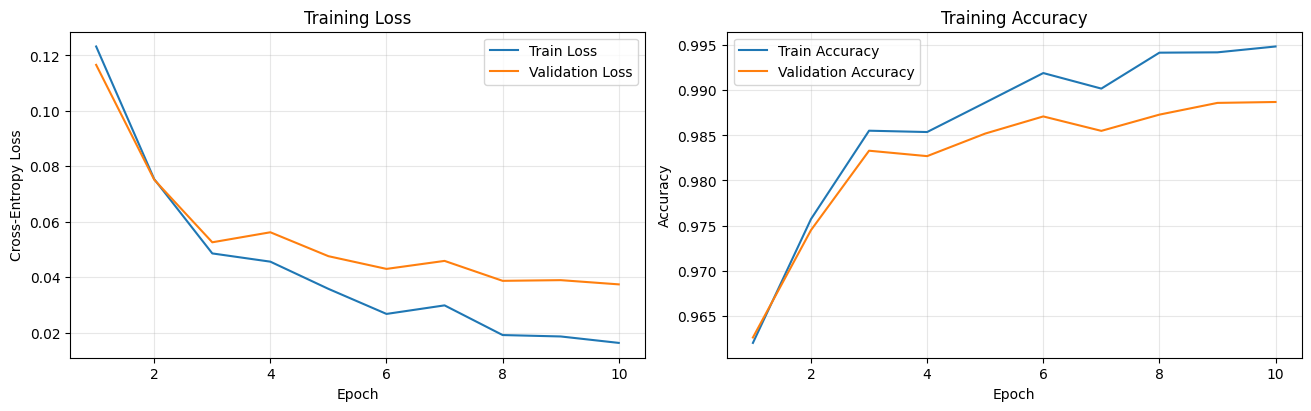

In [55]:
fig, ax = plt.subplots(ncols=2, figsize=(13, 4), layout="constrained")

epochs = np.arange(1, len(data) + 1)

ax[0].plot(epochs, data["train_losses"], label="Train Loss")
ax[0].plot(epochs, data["val_losses"], label="Validation Loss")
ax[0].set(xlabel="Epoch", ylabel="Cross-Entropy Loss", title="Training Loss")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(epochs, data["train_accuracy_scores"], label="Train Accuracy")
ax[1].plot(epochs, data["val_accuracy_scores"], label="Validation Accuracy")
ax[1].set(xlabel="Epoch", ylabel="Accuracy", title="Training Accuracy")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.show()

## Confusion Matrix

In [56]:
cnf_mat_data = pd.read_csv("./checkpoints/confusion_matrix.csv")
cnf_mat_data.head()

,0,1,2,3,4,5,6,7,8,9
0,615,1,1,0,0,0,1,0,1,1
1,0,714,0,0,0,0,0,2,2,0
2,2,2,597,1,2,0,1,4,4,1
3,0,1,1,605,0,3,0,1,3,0
4,0,0,0,0,527,0,1,0,1,3


[Text(0.5, 1.0, 'Confusion Matrix'),
 Text(0.5, 36.72222222222221, 'Predicted Label'),
 Text(104.7222222222223, 0.5, 'True Label')]

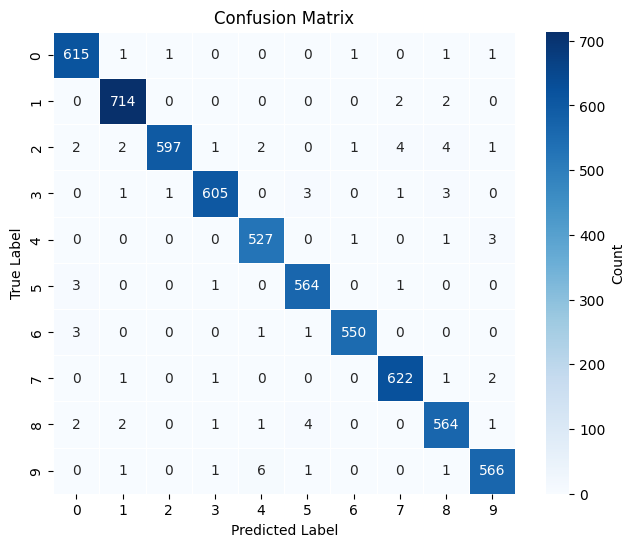

In [57]:
cnf_matrix = cnf_mat_data.to_numpy()

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cnf_mat_data,
    annot=True,
    fmt="d",
    cmap="Blues",
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Count"},
    ax=ax,
)

ax.set(
    title="Confusion Matrix",
    xlabel="Predicted Label",
    ylabel="True Label",
)